# Exercício 3 · ANOVA e post hoc: os lembretes do Fala

**Disciplina 4 · Testes de Hipótese e Experimentação · Pós-graduação em Ciência de Dados e IA · UNIPDS**

**GABARITO** · com prompts, código e leituras comentadas.

## O contexto

O **Fala** é um app para aprender idiomas. Todo dia, às 19h, ele manda um lembrete genérico: *"Hora de praticar!"*. O time de Engajamento criou três versões novas do lembrete e quer saber se alguma faz o usuário praticar mais.

| Versão | O lembrete |
|:---|:---|
| `A_atual` | O lembrete genérico das 19h (controle) |
| `B_horario` | Enviado no horário em que o usuário costuma praticar |
| `C_sequencia` | Mostra a sequência de dias seguidos de prática ("Não perca seus 6 dias!") |
| `D_tutor` | Uma mensagem curta escrita por um tutor, diferente a cada dia |

**O desenho do teste**

| Peça | Decisão |
|:---|:---|
| Unidade sorteada | O **usuário novo**, no cadastro, com 25% de chance para cada versão |
| Métrica | `minutos_14d`: minutos de prática nos 14 dias após o cadastro |
| Custo | As versões A, B e C são automáticas. A versão D exige uma equipe escrevendo mensagens todo dia |

**Os dados**

| Arquivo | O que tem |
|:---|:---|
| `historico_lembretes.csv` | Usuários das 6 semanas antes do teste, todos com o lembrete atual |
| `experimento_lembretes.csv` | Usuários sorteados durante o teste, com a coluna `versao` |

| Coluna | Descrição |
|:---|:---|
| `user_id` | Identificador do usuário |
| `versao` | Versão sorteada do lembrete (só no experimento) |
| `data_cadastro` | Data do cadastro |
| `plataforma` | `android` ou `ios` |
| `minutos_14d` | Minutos de prática nos 14 dias após o cadastro |

### Como usar este gabarito

Cada passo tem o **prompt** usado, o código gerado e a **leitura** do resultado. Os prompts são um exemplo: o importante é que digam **o que** a análise precisa fazer, não **como** codificar. **Todos os testes são bicaudais.**

## Parte 0 · Preparação

**Prompt para a IA**

> Vou analisar um experimento com quatro grupos em Python. Prepare o ambiente com as bibliotecas que vamos usar para manipular dados, fazer gráficos e fazer estatística (ANOVA, comparações múltiplas e cálculo de tamanho de amostra). Use funções prontas sempre que possível e escreva um código simples, para iniciantes.
> Deixe definidos os parâmetros do estudo: nível de significância de 5%, poder de 80% e menor efeito que importa de 10 minutos de prática.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.power import FTestAnovaPower

ALPHA = 0.05
PODER = 0.80
MDE_MINUTOS = 10      # minutos em 14 dias

**Prompt para a IA**

> Carregue os arquivos historico_lembretes.csv (histórico) e experimento_lembretes.csv (experimento), converta a data de cadastro para data e mostre as primeiras linhas, o tamanho e os tipos das colunas do histórico.

In [10]:
hist = pd.read_csv(r"C:\Users\renat\Downloads\historico_lembretes.csv", parse_dates=["data_cadastro"])
exp = pd.read_csv(r"C:\Users\renat\Downloads\experimento_lembretes.csv", parse_dates=["data_cadastro"])

print(hist.shape)
print(hist.dtypes)
hist.head()

(5841, 4)
user_id                   int64
data_cadastro    datetime64[ns]
plataforma               object
minutos_14d               int64
dtype: object


,user_id,data_cadastro,plataforma,minutos_14d
0,200001,2026-06-22,android,95
1,200002,2026-06-22,android,39
2,200003,2026-06-22,ios,29
3,200004,2026-06-22,ios,48
4,200005,2026-06-22,android,62


## Parte 1 · As hipóteses e o plano de análise

Antes de rodar o teste, o time definiu:

| Ingrediente | Valor |
|:---|:---|
| H0 | μ_A = μ_B = μ_C = μ_D (as quatro versões têm a mesma média de minutos) |
| Ha | Pelo menos uma média é diferente |
| α e poder | 5% e 80% |
| Menor efeito que importa | +10 minutos em alguma versão |
| Teste geral | ANOVA de um fator (de Welch, se as variâncias forem diferentes) |
| Post hoc | Tukey: comparar **todos os pares**, porque a decisão é escolher a melhor versão, inclusive entre as novas |

**Por que ANOVA, e não seis testes t?** Com 4 grupos há 6 pares. Seis testes a 5% dariam cerca de 26% de chance de pelo menos um falso positivo. A ANOVA responde com um único teste se **alguma** versão é diferente, e o Tukey compara os pares controlando o erro da família inteira.

**Por que Tukey, e não Dunnett?** O Dunnett compara cada versão nova só com a atual. Aqui a pergunta é mais ampla: se duas versões novas baterem a atual, o time precisa saber se uma é melhor que a outra, porque a D custa caro.

## Parte 2 · Planejamento: quantos usuários precisamos?

O tamanho de amostra é calculado **antes** do teste, com os dados do histórico. Ele precisa atender duas exigências:

1. a **regra de Kohavi**, para que o TLC garanta médias aproximadamente Normais em cada versão;
2. o **poder da ANOVA** para detectar o menor efeito que importa (+10 minutos).

O tamanho do teste é o **maior** dos dois.

**Prompt para a IA**

> No histórico, quero entender o fluxo de usuários: período coberto, total de usuários e média de cadastros por dia.
> Depois, para os minutos de prática em 14 dias, calcule a média com o intervalo de confiança de 95%, o desvio-padrão, a mediana e a assimetria, e mostre um histograma.

Período: 2026-06-22 a 2026-08-02
Usuários: 5841
Cadastros por dia (média): 139

Minutos: média 88.6 · IC 95%: 87.5 a 89.7
Desvio-padrão 44.1 · mediana 81 · assimetria 0.99


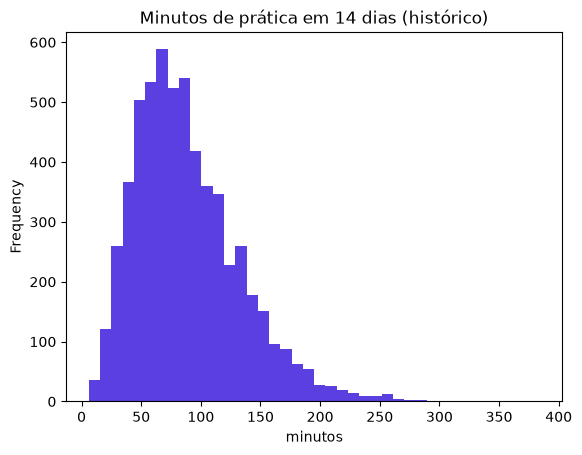

In [11]:
print("Período:", hist["data_cadastro"].min().date(), "a", hist["data_cadastro"].max().date())
print("Usuários:", len(hist))
cadastros_dia = hist.groupby("data_cadastro").size().mean()
print(f"Cadastros por dia (média): {cadastros_dia:.0f}")

minutos = hist["minutos_14d"]
ic = stats.t.interval(1 - ALPHA, len(minutos) - 1, loc=minutos.mean(), scale=stats.sem(minutos))
sigma = minutos.std()
assimetria = stats.skew(minutos)
print(f"\nMinutos: média {minutos.mean():.1f} · IC 95%: {ic[0]:.1f} a {ic[1]:.1f}")
print(f"Desvio-padrão {sigma:.1f} · mediana {minutos.median():.0f} · assimetria {assimetria:.2f}")

minutos.plot.hist(bins=40, color="#5B3FE0")
plt.title("Minutos de prática em 14 dias (histórico)")
plt.xlabel("minutos")
plt.show()

> **Leitura.** O histórico cobre 6 semanas (22/jun a 2/ago), com 5.841 usuários, cerca de **139 cadastros por dia**. Com o lembrete atual, o usuário pratica em média **88,6 minutos** nos primeiros 14 dias (IC de 87,5 a 89,7), com desvio-padrão de 44,1 minutos. A distribuição é assimétrica à direita (mediana de 81, assimetria de 0,99): muita gente pratica pouco e alguns praticam muito.

**Prompt para a IA**

> Calcule o tamanho mínimo de amostra por versão pela regra de Kohavi, n > 355 × assimetria², usando a assimetria dos minutos no histórico. Mostre também o total para as quatro versões.

In [12]:
n_kohavi = 355 * assimetria ** 2
print(f"Kohavi: pelo menos {n_kohavi:.0f} usuários por versão · {4 * n_kohavi:.0f} no total")

Kohavi: pelo menos 350 usuários por versão · 1399 no total


> **Leitura.** Com assimetria de 0,99, a regra pede pelo menos **350 usuários por versão** (cerca de 1.400 no total) para que a média de cada versão se comporte como Normal. Abaixo disso, a ANOVA não seria confiável.

**Prompt para a IA**

> Calcule o tamanho de amostra para a ANOVA com quatro versões. O cenário do menor efeito que importa é: três versões com a média do histórico e uma com 10 minutos a mais. Calcule o tamanho de efeito f de Cohen (o desvio-padrão das quatro médias em torno da média geral, dividido pelo desvio-padrão do histórico) e o número total de usuários para α = 5% e poder de 80%.

In [ ]:
mu0 = minutos.mean()
medias_cenario = np.array([mu0, mu0, mu0, mu0 + MDE_MINUTOS]) # o cenário “três versões iguais à atual e uma com +10 minutos"
sigma_medias = np.std(medias_cenario)       # desvio das médias (divide por k)
f = sigma_medias / sigma
print(f"f de Cohen: {sigma_medias:.2f} / {sigma:.1f} = {f:.3f}")

n_anova = FTestAnovaPower().solve_power(effect_size=f, k_groups=4, alpha=ALPHA, power=PODER)
print(f"ANOVA: {n_anova:.0f} usuários no total · {n_anova / 4:.0f} por versão")

f de Cohen: 4.33 / 44.1 = 0.098
ANOVA: 1134 usuários no total · 284 por versão


> **Leitura.** No cenário do MDE, as médias se espalham com desvio de 4,3 minutos em torno da média geral, contra um ruído de 44,1 minutos: **f = 0,098**, um efeito pequeno. Para detectá-lo com 80% de poder, a ANOVA precisa de **1.134 usuários** no total, 284 por versão.

**Prompt para a IA**

> Junte as duas exigências (Kohavi e ANOVA) e mostre o número total de usuários necessário, que é o maior dos dois. Com a média de cadastros por dia do histórico, calcule quantos dias de teste são necessários e arredonde para semanas completas.

In [14]:
exigencias = pd.Series({"Kohavi": 4 * n_kohavi, "ANOVA": n_anova})
print(exigencias.round(0))

n_total = exigencias.max()
dias = n_total / cadastros_dia
semanas = int(np.ceil(dias / 7))
print(f"\nN necessário: {n_total:.0f} usuários ({n_total / 4:.0f} por versão)")
print(f"Dias necessários: {dias:.1f} → {semanas} semanas completas ({7 * semanas} dias)")

Kohavi    1399.0
ANOVA     1134.0
dtype: float64

N necessário: 1399 usuários (350 por versão)
Dias necessários: 10.1 → 2 semanas completas (14 dias)


> **Leitura.** Aqui a exigência que manda é a do **TLC: 1.399 usuários, 350 por versão**, acima dos 1.134 que a ANOVA pediria para ter poder. Com 139 cadastros por dia, são cerca de 10 dias. Arredondando para semanas completas, por causa do padrão semanal de cadastros, o teste deve durar **2 semanas (14 dias)**.

## Parte 3 · O teste rodou: a amostra e o sorteio

**Prompt para a IA**

> Mostre o período do experimento e quantos usuários caíram em cada versão. Confira se cada versão atingiu o mínimo por versão calculado no planejamento.

In [15]:
print("Período:", exp["data_cadastro"].min().date(), "a", exp["data_cadastro"].max().date())

contagem = exp["versao"].value_counts().sort_index()
minimo_por_versao = n_total / 4
print(pd.DataFrame({"usuarios": contagem, "atingiu o mínimo?": contagem >= minimo_por_versao}))
print(f"Total: {contagem.sum()} · mínimo por versão: {minimo_por_versao:.0f}")



Período: 2026-08-03 a 2026-08-16
             usuarios  atingiu o mínimo?
versao                                  
A_atual           512               True
B_horario         489               True
C_sequencia       497               True
D_tutor           452               True
Total: 1950 · mínimo por versão: 350


> **Leitura.** O teste rodou de 3 a 16 de agosto, 2 semanas completas, com **1.950 usuários**. Todas as versões passaram do mínimo de 350: a menor, D, tem 452. 

## Parte 4 · Descrição e premissas

A ANOVA tem três premissas: **observações independentes**, **médias aproximadamente Normais** em cada grupo e **variâncias parecidas** (só para a ANOVA clássica). Elas não se "provam" com p-valores: cada uma tem a sua forma de ser verificada.

**Independência.** Vem do **desenho**, não de um teste. Cada linha é um usuário diferente, sorteado individualmente, e a métrica é medida por usuário. Está garantida.

**Prompt para a IA**

> Para cada versão do lembrete, calcule o número de usuários, a média, o desvio-padrão, a mediana e a assimetria dos minutos de prática em 14 dias. Mostre um boxplot dos minutos por versão e um gráfico com a média de cada versão e o seu intervalo de confiança de 95%.

             count   mean   std  median  skew
versao                                       
A_atual        512   86.3  43.5    78.0   1.1
B_horario      489   92.3  44.9    87.0   1.0
C_sequencia    497  102.3  52.9    94.0   0.9
D_tutor        452   97.5  48.4    91.0   0.9


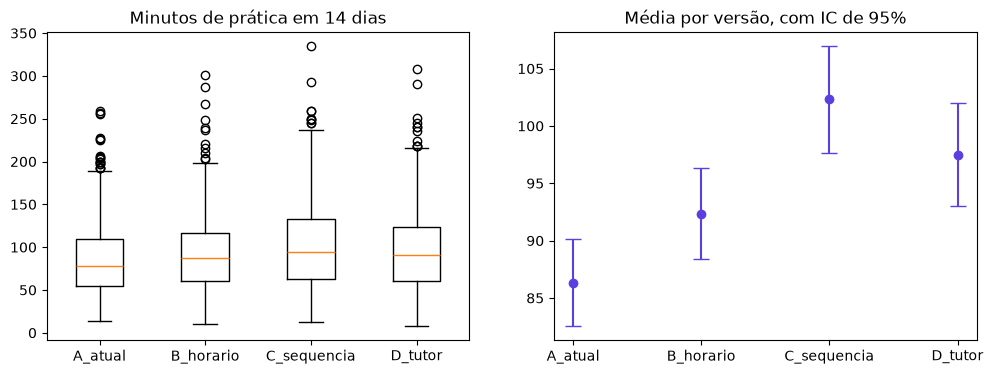

In [16]:
resumo = exp.groupby("versao")["minutos_14d"].agg(["count", "mean", "std", "median", "skew"])
print(resumo.round(1))

versoes = sorted(exp["versao"].unique())
grupos = [exp.loc[exp["versao"] == v, "minutos_14d"] for v in versoes]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].boxplot(grupos)
ax[0].set_xticks(range(1, 5), versoes)
ax[0].set_title("Minutos de prática em 14 dias")

medias = [x.mean() for x in grupos]
erros = [x.mean() - stats.t.interval(1 - ALPHA, len(x) - 1, loc=x.mean(), scale=stats.sem(x))[0]
         for x in grupos]
ax[1].errorbar(versoes, medias, yerr=erros, fmt="o", capsize=6, color="#5B3FE0")
ax[1].set_title("Média por versão, com IC de 95%")
plt.show()

In [29]:
grupos

[0        78
 9        54
 10       58
 11       77
 18      131
        ... 
 1930    104
 1931     37
 1938     30
 1945     47
 1946     65
 Name: minutos_14d, Length: 512, dtype: int64,
 1        81
 7        38
 12      104
 13       30
 17       95
        ... 
 1907     71
 1927    129
 1932     75
 1936    162
 1939     88
 Name: minutos_14d, Length: 489, dtype: int64,
 3       120
 5        32
 14      113
 21      259
 25      107
        ... 
 1941     91
 1942    120
 1943    189
 1947    110
 1949    166
 Name: minutos_14d, Length: 497, dtype: int64,
 2        58
 4        68
 6        82
 8        86
 15       93
        ... 
 1928     90
 1929     75
 1937     60
 1944     90
 1948    114
 Name: minutos_14d, Length: 452, dtype: int64]

> **Leitura.** As médias vão de 86,3 minutos (A, atual) a 102,3 (C, sequência), com B em 92,3 e D em 97,5. A distribuição é assimétrica à direita em todas as versões, e os desvios-padrão vão de 43 a 53 minutos. Os ICs de A e C não se encostam, o que sugere uma diferença real, mas comparar ICs individuais "a olho" não controla o erro das várias comparações. Quem decide são a ANOVA e o post hoc.

## Parte 5 · A ANOVA

**Prompt para a IA**

> Teste se a média de minutos é a mesma nas quatro versões. Rode a ANOVA de Welch e mostre a estatística F e o p-valor de cada uma.

In [17]:

anova_welch = anova_oneway(grupos, use_var="unequal")
print(f"ANOVA de Welch: F = {anova_welch.statistic:.2f} · p-valor = {anova_welch.pvalue:.1e}")



ANOVA de Welch: F = 10.35 · p-valor = 1.0e-06


> **Leitura.** No multiverso em que as quatro versões são equivalentes, uma variação entre as médias tão grande quanto essa praticamente nunca apareceria. **Rejeitamos H0: pelo menos uma versão tem média diferente.**
>


## Parte 6 · O post hoc 

**Prompt para a IA**

> A ANOVA rejeitou H0. Agora compare todos os pares de versões com o teste post hoc de games howells. Monte uma tabela com cada par, a diferença de médias, o intervalo de confiança de 95% simultâneo e o p-valor ajustado, ordenada pela diferença.

In [ ]:

import pingouin as pg


# Games-Howell: todos os pares, cada par com as variâncias dos próprios grupos
gh = pg.pairwise_gameshowell(data=exp, dv="minutos_14d", between="versao")
gh


,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges
0,A_atual,B_horario,86.339844,92.347648,-6.007805,2.793851,-2.150367,993.036205,0.138127,-0.135965
1,A_atual,C_sequencia,86.339844,102.311871,-15.972027,3.052040,-5.233230,959.464601,0.000001,-0.330239
2,A_atual,D_tutor,86.339844,97.497788,-11.157944,2.978856,-3.745715,913.237826,0.001095,-0.243181
3,B_horario,C_sequencia,92.347648,102.311871,-9.964223,3.120894,-3.192746,963.231283,0.007922,-0.202939
4,B_horario,D_tutor,92.347648,97.497788,-5.150139,3.049363,-1.688923,917.142512,0.330083,-0.110441
5,C_sequencia,D_tutor,102.311871,97.497788,4.814084,3.287546,1.464340,946.957633,0.459607,0.094704


## Parte 7 · A decisão

**Recomendação: lançar a versão C (sequência de dias).**

- C tem a maior média (102,3 minutos, contra 86,3 da atual): +16,0 minutos (IC de 8,3 a 23,7), cerca de 18% a mais de prática. O ganho passa do MDE de 10 minutos.
- D também bate a atual, mas não se distingue de C (IC de D − C de −12,8 a +3,1). Como exige uma equipe escrevendo mensagens todo dia, não há motivo para pagar esse custo.
- B não mostrou efeito distinguível do acaso.

**Cuidado na comunicação.** "C e D não diferem" não significa que sejam iguais: o IC mostra que C pode ser até 12,8 minutos melhor que D, ou até 3,1 minutos pior. O teste não tem precisão para separar as duas, mas, com custos tão diferentes, a escolha não depende disso.

## Para ir além (opcional)

Se o plano tivesse sido comparar cada versão nova **apenas com a atual**, o post hoc indicado seria o de **Dunnett**. Rodamos aqui só para comparar os métodos; na prática, o método é escolhido **antes** de ver os dados.

**Prompt para a IA**

> Se a pergunta fosse só "alguma versão nova bate a atual?", aplique o teste de Dunnett, com a versão A como controle, e mostre a diferença, o IC de 95% e o p-valor de cada versão nova contra a atual.

In [21]:
controle = exp.loc[exp["versao"] == "A_atual", "minutos_14d"]
novas = [exp.loc[exp["versao"] == v, "minutos_14d"] for v in versoes[1:]]

dunnett = stats.dunnett(*novas, control=controle)
ic_d = dunnett.confidence_interval(confidence_level=1 - ALPHA)
for k, v in enumerate(versoes[1:]):
    dif = novas[k].mean() - controle.mean()
    print(f"{v} − A_atual: {dif:+.1f} min · IC 95%: {ic_d.low[k]:.1f} a {ic_d.high[k]:.1f}"
          f" · p-valor = {dunnett.pvalue[k]:.4f}")

B_horario − A_atual: +6.0 min · IC 95%: -1.1 a 13.1 · p-valor = 0.1161
C_sequencia − A_atual: +16.0 min · IC 95%: 8.9 a 23.0 · p-valor = 0.0000
D_tutor − A_atual: +11.2 min · IC 95%: 3.9 a 18.4 · p-valor = 0.0008


> **Leitura.** O Dunnett chega às mesmas conclusões: C e D batem a atual, e B não (p = 0,12). 